In [51]:
import os, random, numpy as np
import torch, torchvision, torchvision.transforms as T, torch.nn as nn, torch.nn.functional as F
from torchvision.models import ResNet18_Weights, resnet18
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score

print(f"{torch.__version__=}")
print(f"{torchvision.__version__=}")

if torch.cuda.is_available(): 
    device = "cuda"
    print("cuda")
else:
    device = "cpu"
    print("cpu")

torch.__version__='2.14.1+cu130'
torchvision.__version__='0.29.1+cu130'
cuda


In [2]:
resnet18_model = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet18_model.to(device=device)

x = torch.randn((1, 3, 224, 224), device=device, dtype=torch.float32)
out = resnet18_model(x)
out.shape

torch.Size([1, 1000])

In [3]:
from PIL import Image

data_dir = "data/chest_xray"
test_dir = f"{data_dir}/test"
train_dir = f"{data_dir}/train"
val_dir = f"{data_dir}/val"
data = {}

for path in [test_dir, train_dir, val_dir]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = f"{path}/{cls}/"
        data[folder] = os.listdir(folder)
        print(f"{folder} : {len(data[folder])}")

# print(data)

data/chest_xray/test/NORMAL/ : 234
data/chest_xray/test/PNEUMONIA/ : 390
data/chest_xray/train/NORMAL/ : 1341
data/chest_xray/train/PNEUMONIA/ : 3875
data/chest_xray/val/NORMAL/ : 8
data/chest_xray/val/PNEUMONIA/ : 8


In [4]:
normal_imgs = data[f"{train_dir}/NORMAL/"][:3]
pneu_imgs = data[f"{train_dir}/PNEUMONIA/"][:3]

print("Normal Images:")
for img in normal_imgs:
    i = Image.open(f"{train_dir}/NORMAL/{img}")
    print(f"{img} : {i.size} , {i.mode}")

print("PNEUMONIA Images")
for img in pneu_imgs:
    i = Image.open(f"{train_dir}/PNEUMONIA/{img}")
    print(f"{img} : {i.size} , {i.mode}")

Normal Images:
IM-0300-0001.jpeg : (2020, 1565) , L
NORMAL2-IM-1277-0001-0002.jpeg : (1742, 1422) , L
IM-0261-0001.jpeg : (1596, 1330) , L
PNEUMONIA Images
person57_bacteria_270.jpeg : (1144, 832) , L
person654_bacteria_2546.jpeg : (1160, 824) , L
person705_virus_1303.jpeg : (1016, 816) , L


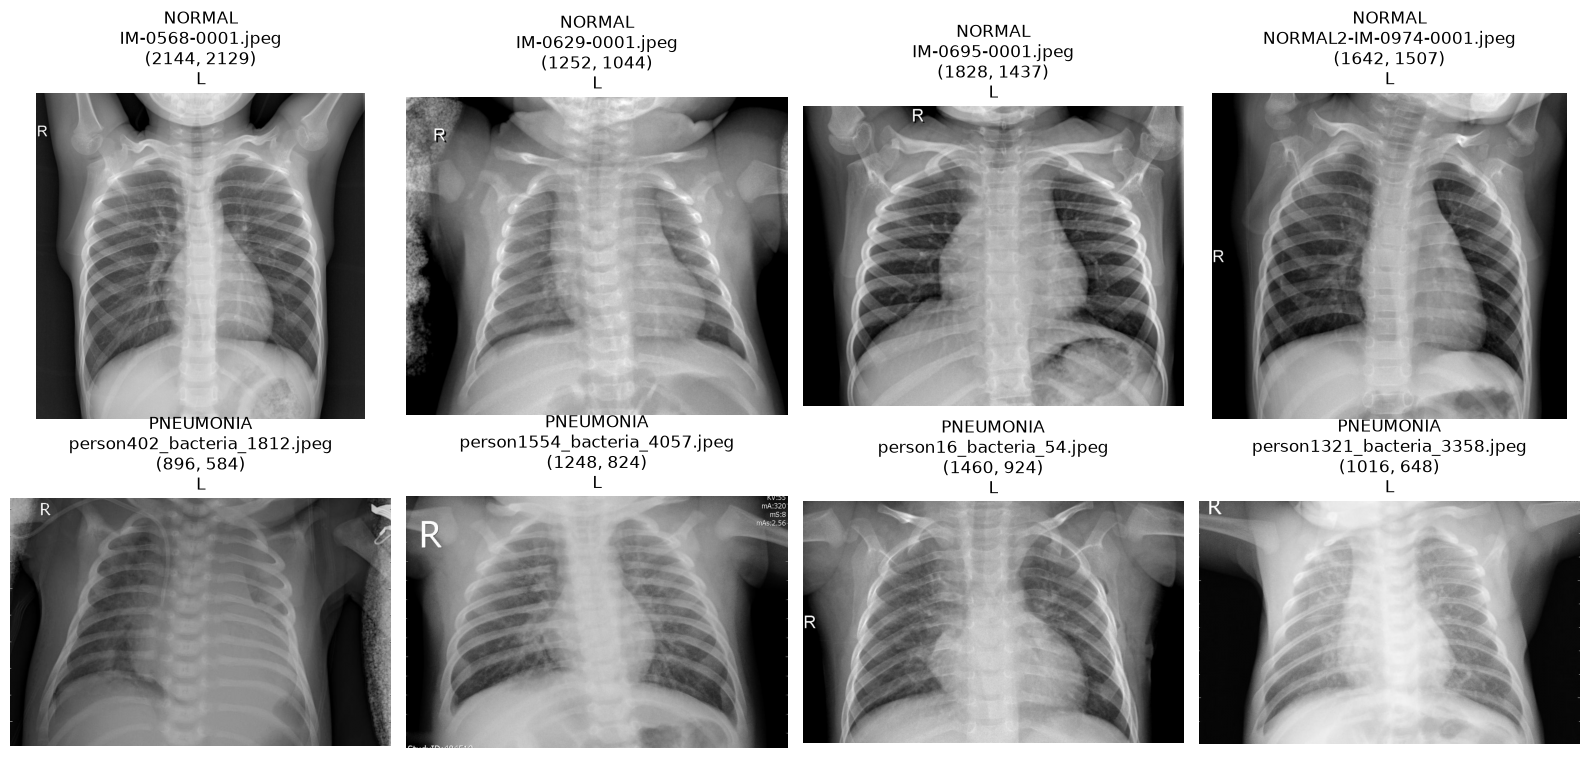

In [5]:

random.seed(3)
normal_imgs_grid = random.sample(data[f"{train_dir}/NORMAL/"], 4)
pneu_imgs_grid = random.sample(data[f"{train_dir}/PNEUMONIA/"], 4)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(len(normal_imgs_grid)):
    n_img, p_img = Image.open(f"{train_dir}/NORMAL/{normal_imgs_grid[i]}"), Image.open(f"{train_dir}/PNEUMONIA/{pneu_imgs_grid[i]}")
    axes[0, i].imshow(n_img, cmap="gray")
    axes[0, i].set_title(f"NORMAL\n{normal_imgs_grid[i]}\n{n_img.size}\n{n_img.mode}")
    axes[0, i].axis("off")
    axes[1, i].imshow(p_img, cmap="gray")
    axes[1, i].set_title(f"PNEUMONIA\n{pneu_imgs_grid[i]}\n{p_img.size}\n{p_img.mode}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

    

In [6]:
dimensions = {}
dimensions["normal"] = []
dimensions["pneumonia"] = []

for img in data[f"{data_dir}/train/NORMAL/"]:
    Img = Image.open(f"{train_dir}/NORMAL/{img}")
    dimensions["normal"].append(Img.size)

for img in data[f"{data_dir}/train/PNEUMONIA/"]:
    Img = Image.open(f"{train_dir}/PNEUMONIA/{img}")
    dimensions["pneumonia"].append(Img.size)

normal_dims = np.array(dimensions["normal"])
pneu_dims = np.array(dimensions["pneumonia"])

print(f"Normal\nmean dimenions = {normal_dims.mean(axis=0)}\nmedian dimensions = {np.median(normal_dims, axis=0)}\nAspect Ratio = {(normal_dims[:, 0] / normal_dims[:, 1]).mean()}\n")
print(f"Pneumonia\nmean dimenions = {pneu_dims.mean(axis=0)}\nmedian dimensions = {np.median(pneu_dims, axis=0)}\nAspect Ratio = {(pneu_dims[:, 0] / pneu_dims[:, 1]).mean()}\n")



Normal
mean dimenions = [1667.73452647 1381.43102163]
median dimensions = [1640. 1328.]
Aspect Ratio = 1.2277920511462639

Pneumonia
mean dimenions = [1200.4836129   825.02683871]
median dimensions = [1168.  776.]
Aspect Ratio = 1.513755093072343



In [7]:
def get_group(name, cls):
    if cls == "PNEUMONIA":
        return name.split("_")[0]          # person1554_bacteria_4057.jpeg -> person1554
    parts = name.split("-")
    i = parts.index("IM")
    return "-".join(parts[:i + 2])         # NORMAL2-IM-1277-0001-0002.jpeg -> NORMAL2-IM-1277

assert get_group("person1554_bacteria_4057.jpeg", "PNEUMONIA") == "person1554"
assert get_group("person23_bacteria_90.jpeg", "PNEUMONIA") == "person23"
assert get_group("IM-0300-0001.jpeg", "NORMAL") == "IM-0300"
assert get_group("NORMAL2-IM-1277-0001-0002.jpeg", "NORMAL") == "NORMAL2-IM-1277"

In [8]:
import pandas as pd

rows = []
for split in ["train", "val"]:            
    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = f"{data_dir}/{split}/{cls}"
        for name in sorted(os.listdir(folder)):
            if name.startswith("."):
                continue
            rows.append({
                "path": f"{folder}/{name}",
                "label": 1 if cls == "PNEUMONIA" else 0,
                "group": get_group(name, cls),
            })

df = pd.DataFrame(rows)

print(f"{len(df)=}")
print(df["label"].mean())
print(df.groupby("label")["group"].nunique())
df.head()

len(df)=5232
0.7421636085626911
label
0    1219
1    1642
Name: group, dtype: int64


,path,label,group
0,data/chest_xray/train/NORMAL/IM-0115-0001.jpeg,0,IM-0115
1,data/chest_xray/train/NORMAL/IM-0117-0001.jpeg,0,IM-0117
2,data/chest_xray/train/NORMAL/IM-0119-0001.jpeg,0,IM-0119
3,data/chest_xray/train/NORMAL/IM-0122-0001.jpeg,0,IM-0122
4,data/chest_xray/train/NORMAL/IM-0125-0001.jpeg,0,IM-0125


In [9]:
# splitting data in 85 train and 15 val

splitter = GroupShuffleSplit(n_splits=1, test_size=.15, random_state=42)
train_idx, val_idx = next(splitter.split(df, df["label"], groups=df["group"]))

train_df = df.iloc[train_idx]
val_df = df.iloc[val_idx]

print(f"traindf length = {len(train_df)}")
print(f"mean = {train_df["label"].mean()}\n")

print(f"valdf length = {len(val_df)}")
print(f"mean = {val_df["label"].mean()}")

print(len(set(train_df["group"]) & set(val_df["group"])))

os.makedirs("splits", exist_ok=True)
train_df.to_csv("splits/train.csv", index=False)
val_df.to_csv("splits/val.csv", index=False)

traindf length = 4453
mean = 0.745340220076353

valdf length = 779
mean = 0.72400513478819
0


## Dataset and transforms

In [10]:
mean = [0.485, 0.456, 0.406]   # ImageNet stats, what the pretrained ResNet expects
std  = [0.229, 0.224, 0.225]

val_tf = T.Compose([
    T.Resize(224),             # shorter side -> 224, keeps shape (ONE number, not two)
    T.CenterCrop(224),         # middle 224x224 square
    T.ToTensor(),              # (H,W,C) 0-255  ->  (C,H,W) 0.0-1.0
    T.Normalize(mean, std),    # (x - mean) / std per channel
])

train_tf = T.Compose([
    T.Resize(224),
    T.RandomRotation(10),      # random tilt, -10 to +10 degrees, new every epoch
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean, std),
])


In [11]:
img = Image.open(train_df["path"].iloc[0]).convert("RGB")

x = val_tf(img)
print(x.shape, x.min(), x.max())    # torch.Size([3, 224, 224]), about -2 ... +2.5

a, b = train_tf(img), train_tf(img)
print(torch.equal(a, b))            # False: the rotation is random each time

torch.Size([3, 224, 224]) tensor(-2.1179) tensor(2.5180)
False


In [33]:
import pandas as pd
from torch.utils.data import Dataset, DataLoader

class XrayDataset(Dataset):

    def __init__(self, csv_path, transform):
        self.df = pd.read_csv(csv_path)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):        
        img_path = self.df["path"].iloc[i]
        img = self.transform(Image.open(img_path).convert("RGB"))
        return img, self.df["label"].iloc[i]

train_ds = XrayDataset("splits/train.csv", train_tf)
val_ds   = XrayDataset("splits/val.csv", val_tf)

print(len(train_ds), len(val_ds))   # 4453 779
x, y = train_ds[0]
print(x.shape, y)                    # torch.Size([3, 224, 224]) 0

4453 779
torch.Size([3, 224, 224]) 0


### DataLoaders

In [45]:
# creates small batches of 32 as we have bigger images
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=4)

xb, yb = next(iter(train_loader))
print(f"{xb.shape=}")
print(f"{yb=}")
print(f"{len(train_loader)=}")

xb.shape=torch.Size([32, 3, 224, 224])
yb=tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0,
        0, 1, 1, 1, 1, 0, 1, 0])
len(train_loader)=140


### All data captured successfully!

### Data Loading time test

In [40]:
import time

start = time.time()

for xb, yb in train_loader:
    pass

print(f"{time.time() - start}s")

6.500061750411987s


## Baseline building

In [46]:
class SmallCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        # block 1: 3 -> 32               (224 -> 112 after pool)
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        # block 2: 32 -> 64              (112 -> 56)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        # block 3: 64 -> 128             (56 -> 28)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        # block 4: 128 -> 256            (28 -> 14)
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn4   = nn.BatchNorm2d(256)
        # block 5: 256 -> 256            (14 -> 7)
        self.conv5 = nn.Conv2d(256, 256, 3, padding=1)
        self.bn5   = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2)              # halves H and W; no weights, so one is reused
        self.gap  = nn.AdaptiveAvgPool2d(1)      # (N, 256, 7, 7) -> (N, 256, 1, 1)
        self.fc   = nn.Linear(256, 2)            # 2 outputs: normal, pneumonia

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.pool(F.relu(self.bn5(self.conv5(x))))
        x = self.gap(x)
        x = torch.flatten(x, 1)      # (N, 256, 1, 1) -> (N, 256)
        x = self.fc(x)
        return x
        

In [47]:
model = SmallCNN().to(device)
out = model(xb.to(device))
print(out.shape)                                   # torch.Size([32, 2])
print(sum(p.numel() for p in model.parameters()))  # about 981,000

torch.Size([32, 2])
980482


In [48]:
def evaluate(model, loader):
    model.eval()                       # BatchNorm: use stored stats, not batch stats
    total_loss, correct, n = 0.0, 0, 0
    all_probs, all_labels = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            total_loss += loss.item() * len(yb)      # sum per-image loss
            correct += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)
            probs = F.softmax(logits, dim=1)[:, 1]
            all_probs.append(probs.cpu())
            all_labels.append(yb.cpu())

    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    return total_loss / n, correct / n, probs, labels


def train(model, epochs=10, lr=0.01):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    for epoch in range(epochs):
        model.train()                  # BatchNorm: use batch stats; dropout on (if any)
        total_loss, n = 0.0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            optimizer.zero_grad()     
            loss.backward()
            optimizer.step()          
            total_loss += loss.item() * len(yb);  
            n += len(yb)

        val_loss, val_acc, _, _ = evaluate(model, val_loader)
        print(f"epoch {epoch+1:2d}  train loss {total_loss/n:.4f}  "
              f"val loss {val_loss:.4f}  val acc {val_acc:.3f}")

In [49]:
torch.manual_seed(7053)
model = SmallCNN().to(device)
train(model, epochs=10)

epoch  1  train loss 0.2613  val loss 0.1708  val acc 0.936
epoch  2  train loss 0.1745  val loss 0.3192  val acc 0.881
epoch  3  train loss 0.1414  val loss 0.2745  val acc 0.895
epoch  4  train loss 0.1302  val loss 0.2541  val acc 0.924
epoch  5  train loss 0.1084  val loss 0.1737  val acc 0.935
epoch  6  train loss 0.0968  val loss 0.1283  val acc 0.956
epoch  7  train loss 0.0979  val loss 0.3851  val acc 0.873
epoch  8  train loss 0.1013  val loss 0.0940  val acc 0.965
epoch  9  train loss 0.0833  val loss 0.0983  val acc 0.968
epoch 10  train loss 0.0717  val loss 0.0842  val acc 0.968


In [52]:
def confusion_counts(probs, labels, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    tp = ((preds == 1) & (labels == 1)).sum()
    fp = ((preds == 1) & (labels == 0)).sum()   # predicted 1, truly 0
    fn = ((preds == 0) & (labels == 1)).sum()   # predicted 0, truly 1
    tn = ((preds == 0) & (labels == 0)).sum()   # predicted 0, truly 0
    return tp, fp, fn, tn


def safe_div(a, b):
    return a / b if b > 0 else 0.0          # guards against 0 / 0


def rates(tp, fp, fn, tn):
    recall      = safe_div(tp, tp + fn)
    specificity = safe_div(tn, tn + fp)
    precision   = safe_div(tp, tp + fp)
    f1          = safe_div(2 * precision * recall, precision + recall)
    return recall, specificity, precision, f1


def roc_auc(probs, labels):
    pos = probs[labels == 1]                # P(pneumonia) for the truly sick
    neg = probs[labels == 0]                # P(pneumonia) for the truly healthy
    wins = (pos[:, None] >  neg[None, :]).mean()   # pneumonia scored higher
    ties = (pos[:, None] == neg[None, :]).mean()   # same score: half a win
    return wins + 0.5 * ties
    

In [53]:
val_loss, val_acc, probs, labels = evaluate(model, val_loader)

tp, fp, fn, tn = confusion_counts(probs, labels)
recall, specificity, precision, f1 = rates(tp, fp, fn, tn)
print(f"TP {tp}  FP {fp}  FN {fn}  TN {tn}   (sum {tp+fp+fn+tn})")
print(f"recall {recall:.4f}  specificity {specificity:.4f}  precision {precision:.4f}  f1 {f1:.4f}")
print(f"AUC  mine {roc_auc(probs, labels):.4f}")

preds = probs >= 0.5
print(confusion_matrix(labels, preds))      # [[TN FP] [FN TP]]
print(f"sklearn  recall {recall_score(labels, preds):.4f}  precision {precision_score(labels, preds):.4f}  "
      f"f1 {f1_score(labels, preds):.4f}  AUC {roc_auc_score(labels, probs):.4f}")

TP 553  FP 14  FN 11  TN 201   (sum 779)
recall 0.9805  specificity 0.9349  precision 0.9753  f1 0.9779
AUC  mine 0.9947
[[201  14]
 [ 11 553]]
sklearn  recall 0.9805  precision 0.9753  f1 0.9779  AUC 0.9947
